In [1]:
# Imports
import re
import torch
import pickle
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [ ]:
# Copies code from github (https://github.com/moeschl21/TransformerLSR_moeschl.git) into the working directory 
!git clone https://github.com/moeschl21/TransformerLSR_moeschl.git
!cp -r TransformerLSR_moeschl/* /kaggle/working/
!rm -rf TransformerLSR_moeschl

In [ ]:
!mkdir -p data results models

In [ ]:
# Copies data from dataset
!cp -r /kaggle/input/datasets/jonasmschl/data-lsr/data_lsr/. /kaggle/working/data/

In [ ]:
# Copies models from dataset
!cp -r /kaggle/input/datasets/jonasmschl/data-lsr/13_censoring_models_LSR/. /kaggle/working/models/

In [2]:
# Setting up variables
num_sim = 100 # Number of Simulations
num_traj = 100 # Number of patients
timeout = 1000 # Maximum visits
batch_size = 16
num_enc_layer = 2 #2
num_dec_layer = 3 #3
lr = 0.0001 #0.0001
model_size = 64 # Embedding size 64
epoch = 100

In [ ]:
########################################################################
############################## EVALUATION ##############################
########################################################################

In [4]:
# Install Module Lifelines for eval.py
!pip install lifelines

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.1/409.1 kB 2.1 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.9/118.9 kB 4.3 MB/s eta 0:00:00
  Created wheel for autograd-gamma: filename=autograd_gamma-0.5.0-py3-none-any.whl size=4030 sha256=c7b8779bf9547891f6b586c90e03a271d079df6ce444563f42f6106f9ee7e1d1
  Stored in directory: /root/.cache/pip/wheels/50/37/21/0a719b9d89c635e89ff24bd93b862882ad675279552013b2fb
Successfully built autograd-gamma


In [5]:
import logging

logger = logging.getLogger()

for handler in logger.handlers[:]:
    logger.removeHandler(handler)

In [33]:
# Evaluating the models and saves the results in the result folder
for seed in range(60,60 + 1):
    print(f"##################### Seed: {seed} #####################")
    !python eval.py \
      --seed {seed} \
      --batch_size {batch_size} \
      --num_enc_layer {num_enc_layer} \
      --num_dec_layer {num_dec_layer} \
      --lr {lr} \
      --model_size {model_size} \
      --local \
      --data DIVAT_sim_missing_{num_traj}_visit_{timeout}_long_3 

    if seed == num_sim:
        print("done")

    logger = logging.getLogger()

    for handler in logger.handlers[:]:
        logger.removeHandler(handler)

##################### Seed: 60 #####################
[ Sat Oct 17 11:41:26 2026 ] Namespace(seed=60, batch_size=16, num_enc_layer=2, num_dec_layer=3, num_head=4, model_size=64, suffix='eval', model='LSR', d_long=3, data='DIVAT_sim_missing_100_visit_1000_long_3', local=True, Y1_missing=0, Y2_missing=0, Y3_missing=0, inten_weight=0.01, surv_weight=0.1, lr=0.0001)
[ Sat Oct 17 11:41:26 2026 ] ==================================================
[ Sat Oct 17 11:41:26 2026 ] Starting evaluation for dataset: DIVAT_sim_missing_100_visit_1000_long_3
[ Sat Oct 17 11:41:26 2026 ] 4 heads, 2 enc layers,3 dec layers, 64 model dimension
[ Sat Oct 17 11:41:26 2026 ] Data containing total 100 trajectories
[ Sat Oct 17 11:41:26 2026 ] ==================================================
LT: 288.5876373441672
pred_times: [ 452.05934834  968.85239116 1300.41059067 1930.95334218 2808.22120676
 4865.73808159]
pred_times[0] - LT: 163.47171099853568


In [6]:
# Calculate censoring rate
censoring_rates = []
files = glob.glob('./data/*.pkl')
for file in files:
    if "Info" in file or "info" in file:
        continue

    with open(file, 'rb') as f:
        res = pickle.load(f)
    deathrate = res.groupby("id")["event"].first().mean()
    censoring_rates.append(1 - deathrate)

censorring_rate = sum(censoring_rates) / len(censoring_rates)

print(f"Censoring rate is: {censorring_rate*100}%")

Censoring rate is: 13.253968253968246%


In [3]:
# Load results and extract seed numbers
results = []
files = sorted(glob.glob('./results/DIVAT_*.pkl'))

for file in files:
    with open(file, 'rb') as f:
        res = pickle.load(f)

    seed = int(re.search(r'_seed(\d+)_', file).group(1))
    res['seed'] = seed
    results.append(res)

df = pd.DataFrame(results)
df = df.sort_values("seed").reset_index(drop=True)

# Seeds excluded from IBS comparison with joineRML
excluded_ibs_seeds = [24]

# Exclude these seeds only from IBS
df.loc[df["seed"].isin(excluded_ibs_seeds), "ibs"] = np.nan

# Define evaluation metrics
metrics = ["Y1err", "Y2err", "Y3err", "ibs", "surv_ll_err", "visit_ll_err"]

# Separate plotting data
df_inten = df[["seed","visit_log_inten_list", "visit_log_inten_truth", "visit_times"]]
df_long = df[["seed","long_times", "Y1_pred", "Y1_truth", "Y2_pred", "Y2_truth", "Y3_pred", "Y3_truth", "long_nan_mask"]]
df_mean_surv = df[["seed","total_pred_plot", "mean_surv_plot", "pred_times_plot"]]

# Keep only evaluation metrics for summary
df_metrics = df[metrics]

# Calculate mean and standard deviation across seeds
summary = pd.DataFrame({
    "mean": df_metrics.mean(axis=0, skipna=True),
    "std": df_metrics.std(axis=0, ddof=1, skipna=True)
})

summary["mean_pm_std"] = (
    summary["mean"].round(3).astype(str) + " ± " +
    summary["std"].round(3).astype(str)
)

summary_metrics = summary.loc[metrics].copy()

# Display results
print(df[["seed"] + metrics])
print(summary_metrics)

    seed     Y1err     Y2err     Y3err       ibs  surv_ll_err  visit_ll_err
0      1  0.356528  0.461434  0.325361  0.226045     1.234965      0.862218
1      2  0.333137  0.588167  0.320786  0.210021     0.880347      0.477758
2      3  0.378960  0.470058  0.339693  0.230726     1.226416      1.033708
3      4  0.245992  0.348632  0.308447  0.204246     0.861935      0.562501
4      5  0.300553  0.407176  0.332912  0.206019     1.090908      0.850154
..   ...       ...       ...       ...       ...          ...           ...
95    96  0.365311  0.431314  0.350670  0.168255     0.885121      1.297721
96    97  0.442454  0.523363  0.320227  0.149170     1.069994      0.929733
97    98  0.294785  0.356846  0.326197  0.211091     1.048012      1.318540
98    99  0.310335  0.435167  0.332225  0.182984     1.171246      1.193086
99   100  0.277646  0.375926  0.312651  0.133916     0.836736      1.242401

[100 rows x 7 columns]
                  mean       std    mean_pm_std
Y1err         0.

In [4]:
# Output the metricsSS
print(f"For censoring rate {censorring_rate*100}%:")
print(f"")
for metric in metrics:
    print(f"{metric:<15} : {summary.loc[metric, "mean_pm_std"]}")

For censoring rate 13.253968253968246%:

Y1err           : 0.352 ± 0.093
Y2err           : 0.461 ± 0.109
Y3err           : 0.329 ± 0.018
ibs             : 0.202 ± 0.043
surv_ll_err     : 1.12 ± 0.401
visit_ll_err    : 1.295 ± 0.478


In [10]:
# Get ground truth for survival plot
for seed in range(1,5 + 1):
    print(f"##################### Predicted Survival: Seed {seed} #####################")
    
    !python oracle_survival.py \
      --data_path /kaggle/input/datasets/jonasmschl/data-lsr/98_withoutmissing/13_censoring/DIVAT_sim_100_visit_1000_long_3_seed_{seed}.pkl \
      --patient_info_path /kaggle/input/datasets/jonasmschl/data-lsr/98_withoutmissing/13_censoring/DIVAT_sim_100_visit_1000_long_3_seed_{seed}_patientInfo.pkl \
      --simulation_py data_simulation.py \
      --n_paths 500 \
      --horizon 16000 \
      --output_path results/predict_survival_seed_{seed}.pkl

##################### Predicted Survival: Seed 1 #####################
[01/19] patient 80: last visit=297.453, LT=354.292, Y3=2.183
[02/19] patient 81: last visit=0.000, LT=354.292, Y3=2.360
^C
Traceback (most recent call last):
  File "/kaggle/working/oracle_survival.py", line 390, in <module>
    main()
  File "/kaggle/working/oracle_survival.py", line 361, in main
    result = compute_oracle_survival(
             ^^^^^^^^^^^^^^^^^^^^^^^^
  File "/kaggle/working/oracle_survival.py", line 285, in compute_oracle_survival
    death_time = simulate_one_oracle_path(
                 ^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/kaggle/working/oracle_survival.py", line 215, in simulate_one_oracle_path
    _, _, done, death, _, _ = env.step(
                              ^^^^^^^^^
  File "/kaggle/working/data_simulation.py", line 392, in step
    Zeta = self.cumulative_prob(t_upper=t_ij,t_lower=self.time,di=di)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/kaggle/work

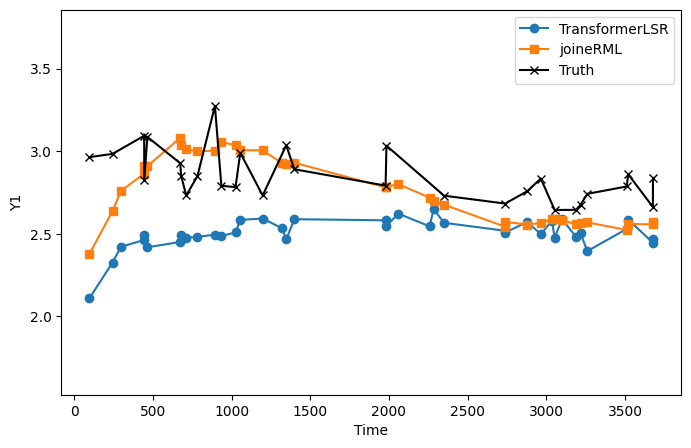

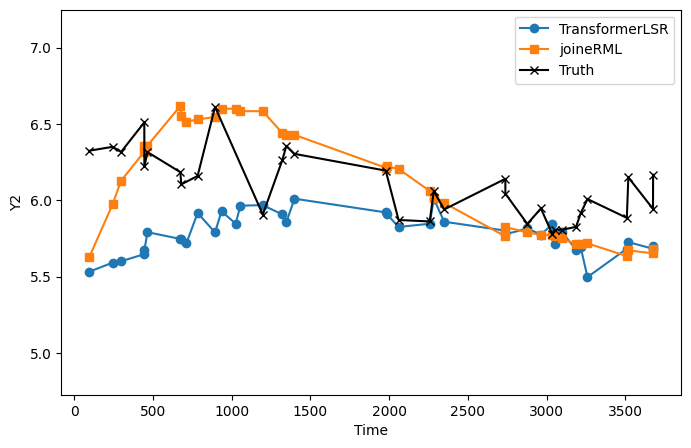

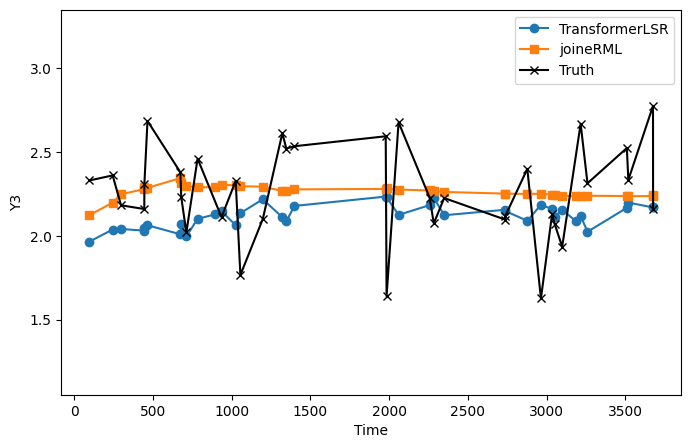

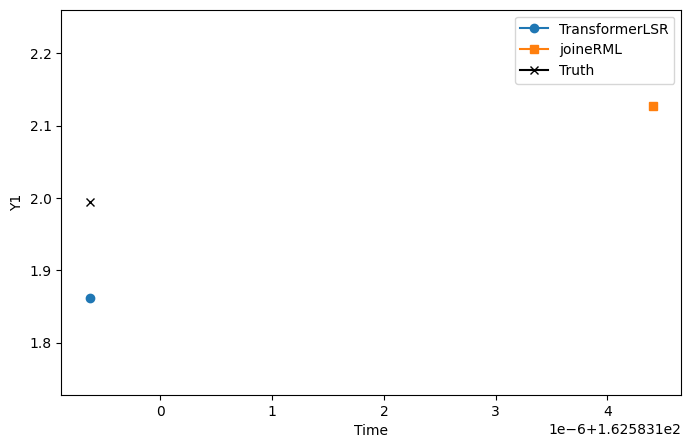

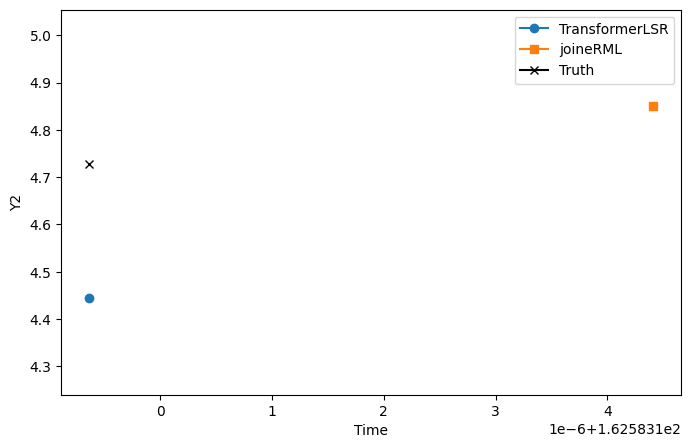

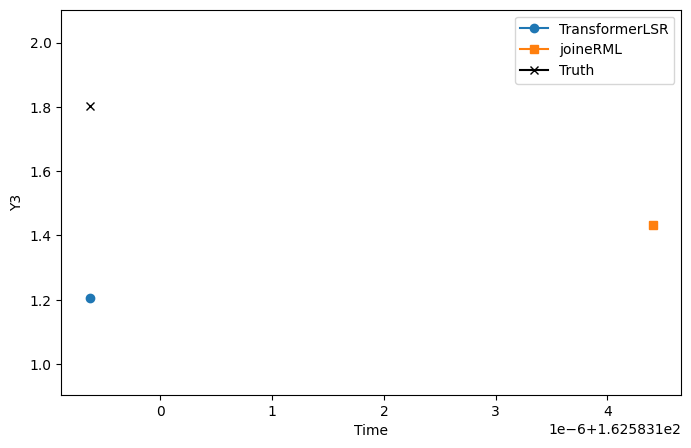

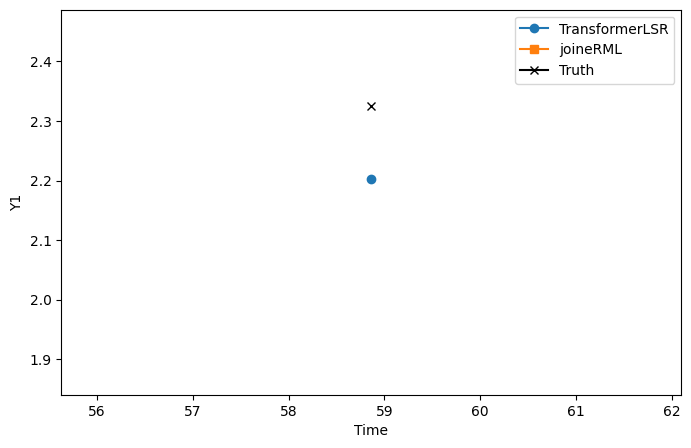

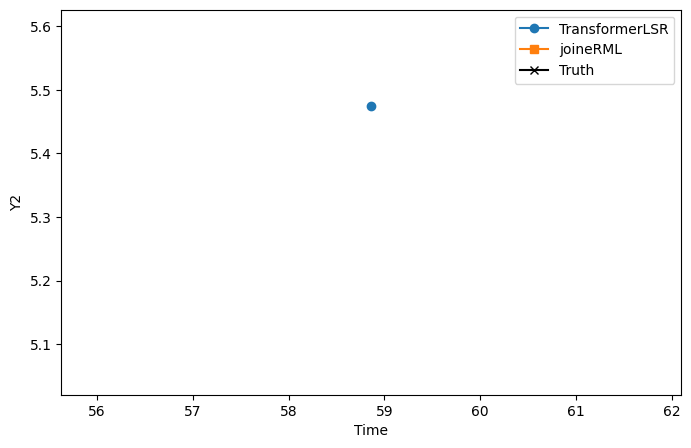

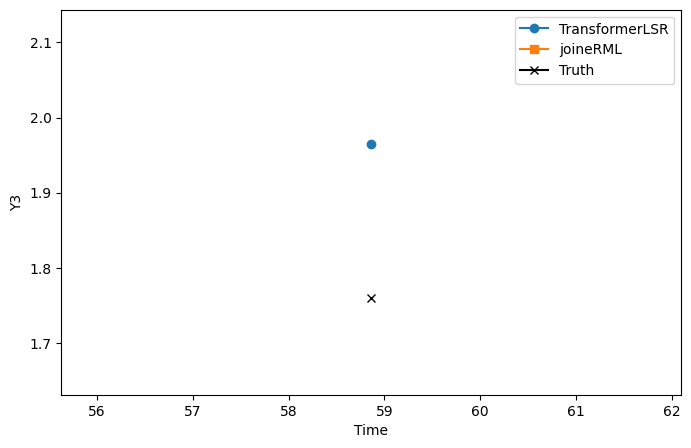

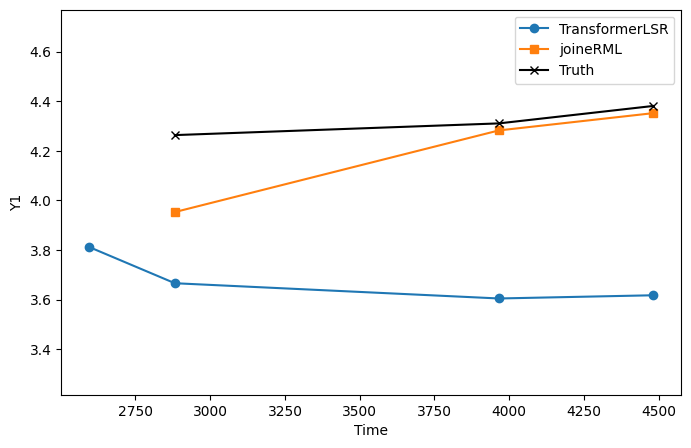

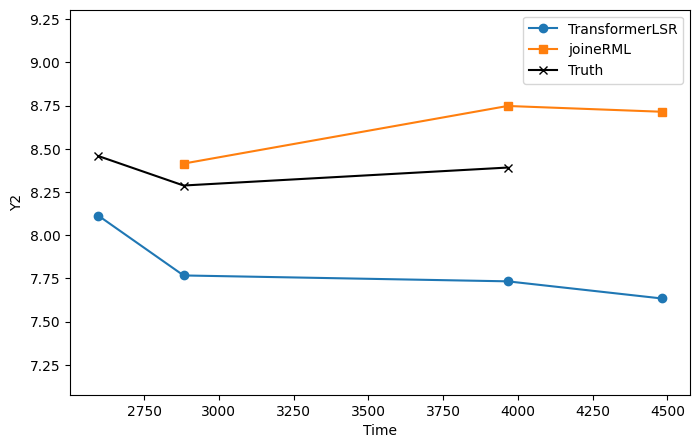

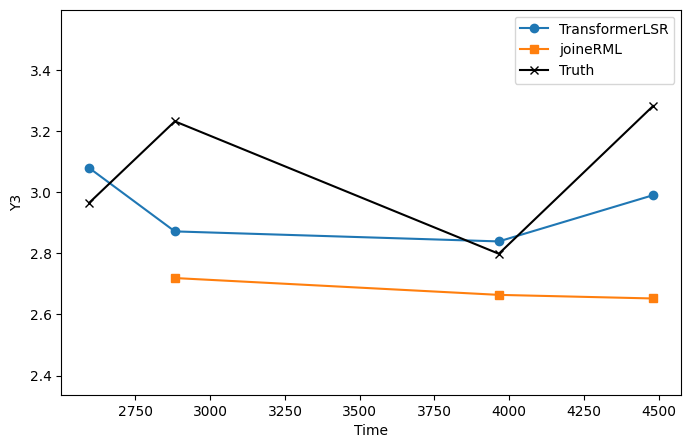

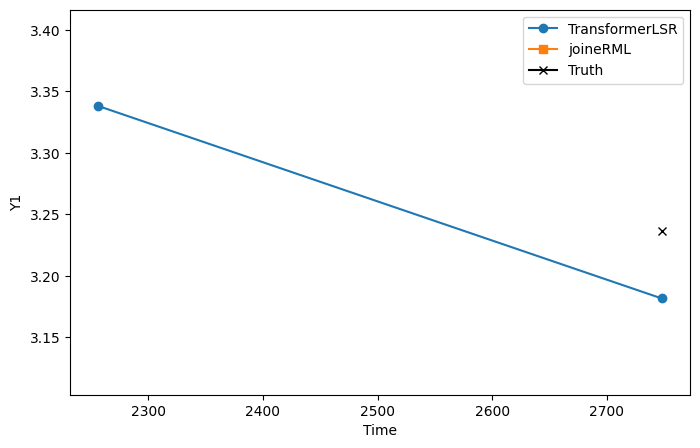

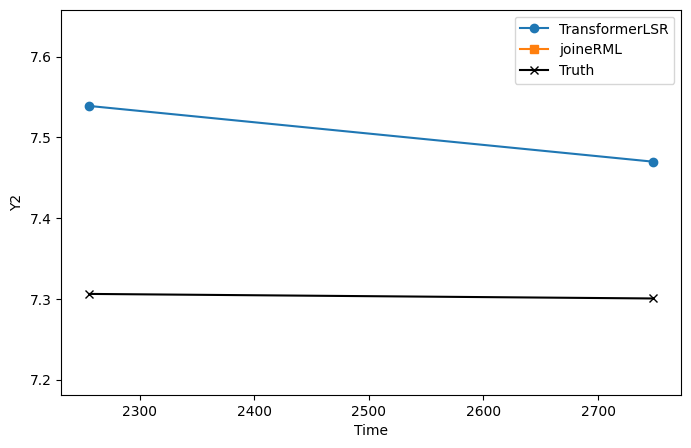

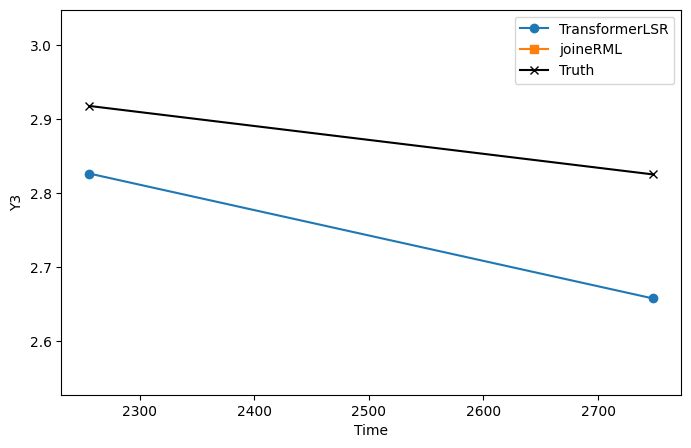

In [21]:
# Plotting longitudinal outcomes
eval_data_path = "/kaggle/input/datasets/jonasmschl/data-lsr/13_eval_data"

for i in range(5):

    seed = i + 1

    times = np.array(df_long.loc[i, "long_times"])
    nan_mask = np.array(df_long.loc[i, "long_nan_mask"])

    # joineRML results for the same seed
    joinerml = pd.read_csv(
        f"{eval_data_path}/long_results_seed_{seed}.csv"
    )

    # Same test patient as TransfomerLSR
    pid = 80

    for j in range(3):

        y = j + 1

        # LSR
        pred = np.array(df_long.loc[i, f"Y{y}_pred"])
        truth = np.array(df_long.loc[i, f"Y{y}_truth"])

        valid = ~nan_mask[:, j]

        # joineRML
        joinerml_y = (
            joinerml[
                (joinerml["id"] == pid) &
                (joinerml["outcome"] == f"Y{y}")
            ]
            .sort_values("obstime")
        )

        plt.figure(figsize=(8, 5))

        # LSR Prediction 
        plt.plot(times[1:], pred[1:], marker="o", label="TransformerLSR")

        # joineRML
        plt.plot(joinerml_y["obstime"].iloc[1:], joinerml_y["predicted"].iloc[1:], marker="s", label="joineRML")

        # Truth only where Y was observerd
        plt.plot(times[1:][valid[1:]], truth[1:][valid[1:]], marker="x", color="black", label="Truth")

        all_values = np.concatenate([
            pred[1:],
            joinerml_y["predicted"].to_numpy(),
            truth[1:][valid[1:]]
        ])
        
        y_min = np.min(all_values)
        y_max = np.max(all_values)
        margin = 0.5 * (y_max - y_min)
        
        plt.ylim(y_min - margin, y_max + margin)
        plt.xlabel("Time")
        plt.ylabel(f"Y{y}")
        #plt.title(f"Seed {seed} - Y{y}")
        plt.legend()
        plt.show()

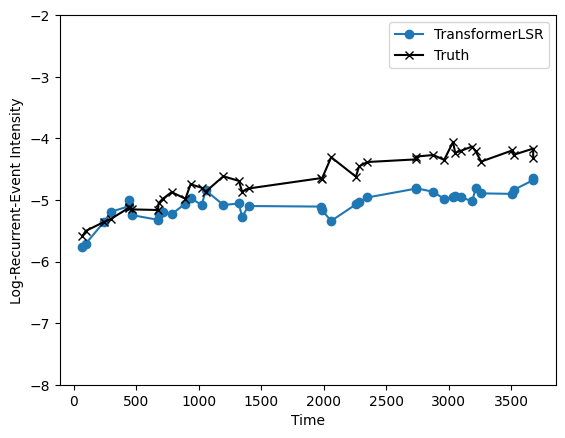

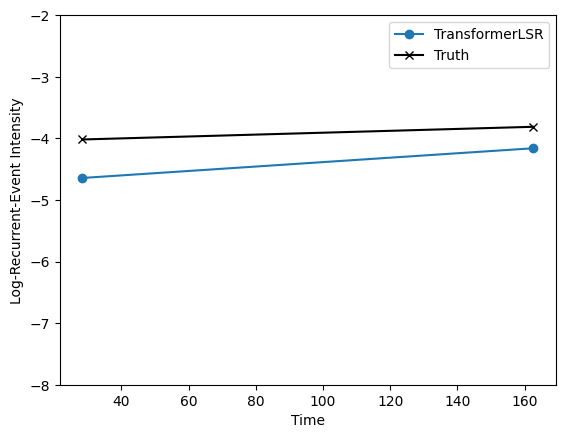

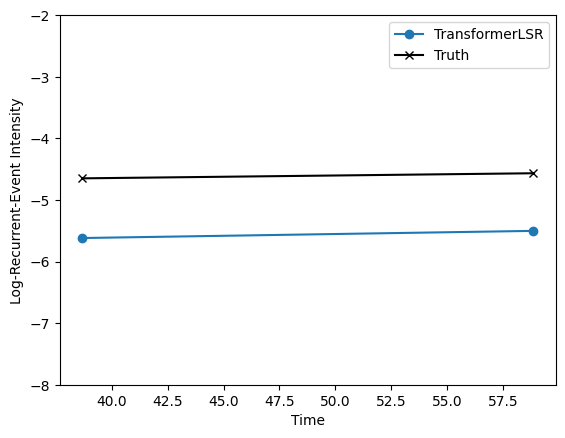

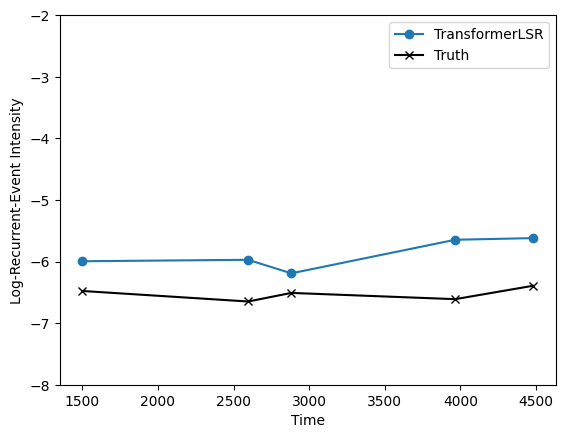

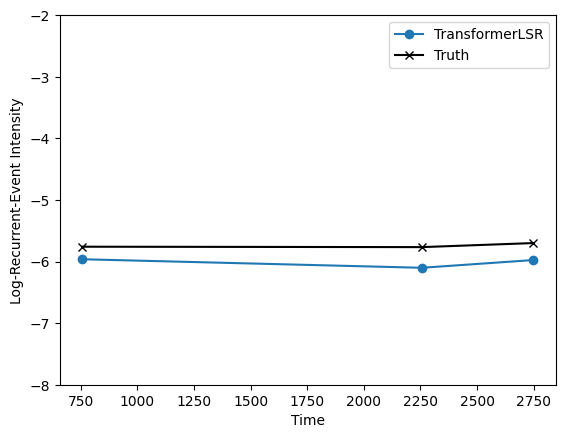

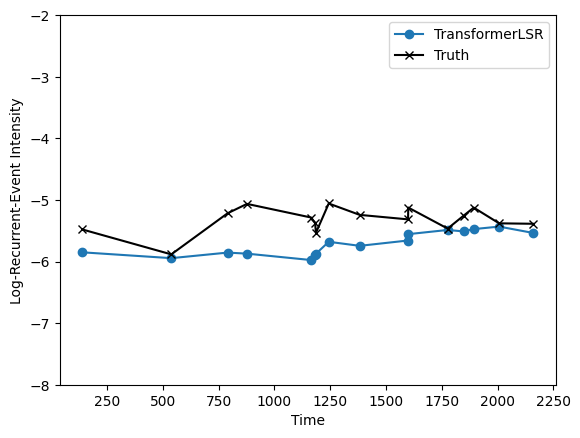

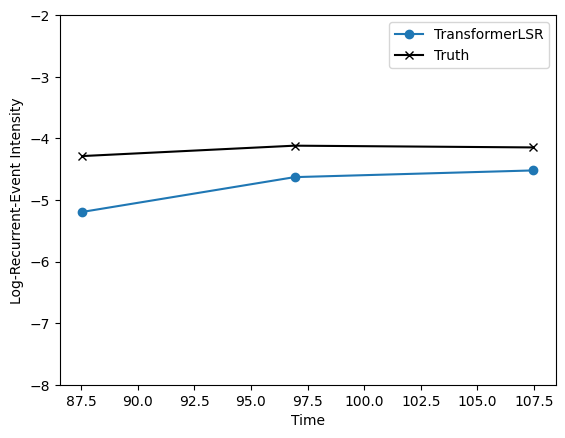

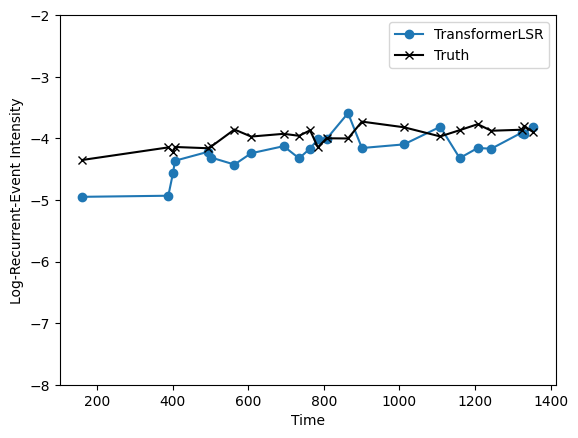

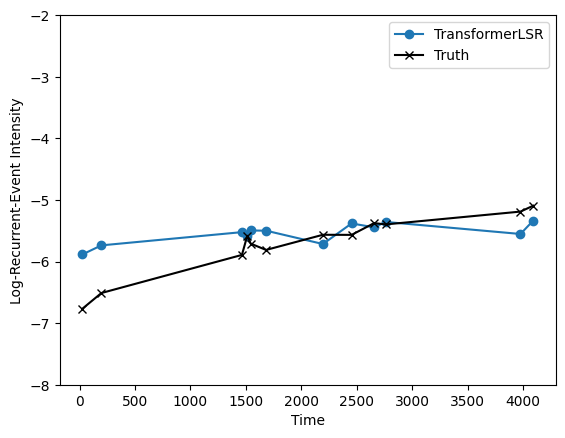

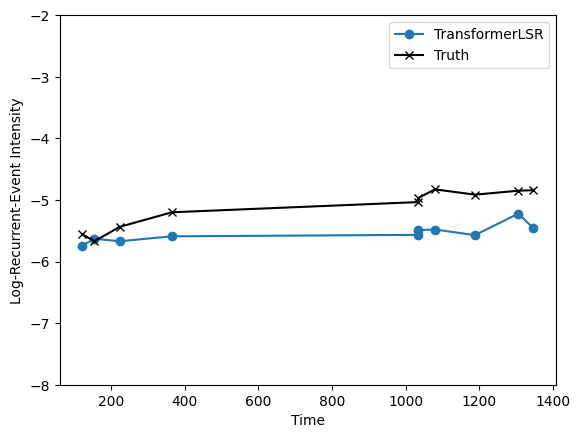

In [24]:
# Plotting recurrent event intensity
for i in range(10):
    plt.figure()
    plt.plot(df_inten["visit_times"][i], df_inten["visit_log_inten_list"][i], marker="o", label="TransformerLSR")
    plt.plot(df_inten["visit_times"][i], df_inten["visit_log_inten_truth"][i], marker="x", color="black", label="Truth")
    

    plt.xlabel("Time")
    plt.ylabel("Log-Recurrent-Event Intensity")
    plt.ylim(-8, -2)
    plt.legend()
    plt.show()

Seed 1: dict_keys(['LT', 'plot_times', 'eligible_test_ids', 'test_ids', 'n_paths', 'horizon', 'oracle_surv_by_patient', 'mean_oracle_surv', 'start_rows', 'mc_seed'])


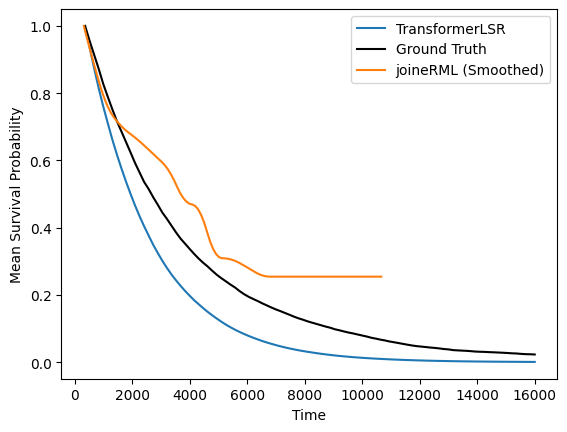

Seed 2: dict_keys(['LT', 'plot_times', 'eligible_test_ids', 'test_ids', 'n_paths', 'horizon', 'oracle_surv_by_patient', 'mean_oracle_surv', 'start_rows', 'mc_seed'])


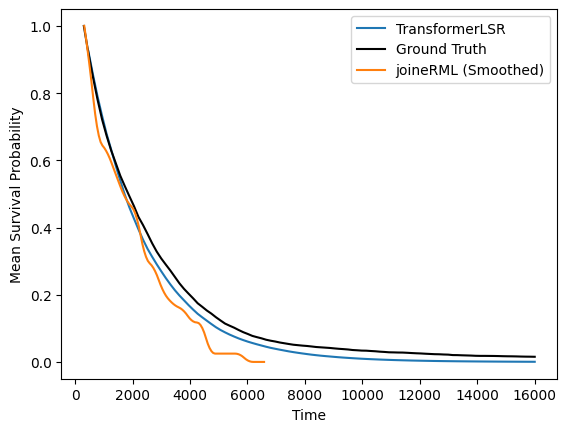

Seed 3: dict_keys(['LT', 'plot_times', 'eligible_test_ids', 'test_ids', 'n_paths', 'horizon', 'oracle_surv_by_patient', 'mean_oracle_surv', 'start_rows', 'mc_seed'])


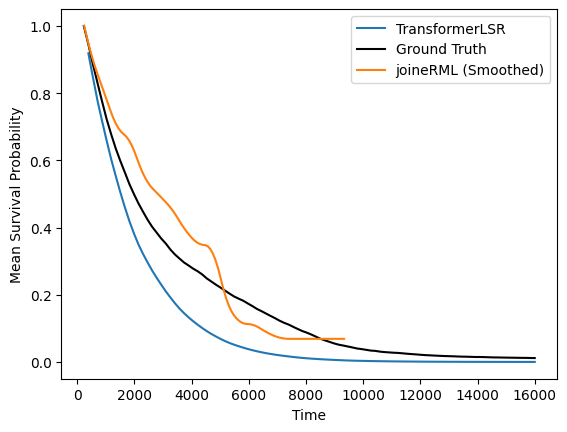

Seed 4: dict_keys(['LT', 'plot_times', 'eligible_test_ids', 'test_ids', 'n_paths', 'horizon', 'oracle_surv_by_patient', 'mean_oracle_surv', 'start_rows', 'mc_seed'])


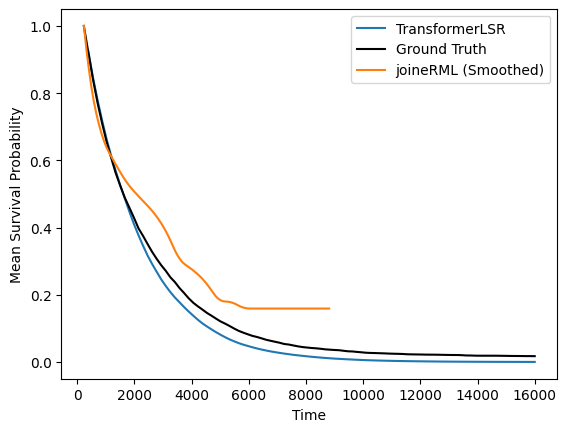

Seed 5: dict_keys(['LT', 'plot_times', 'eligible_test_ids', 'test_ids', 'n_paths', 'horizon', 'oracle_surv_by_patient', 'mean_oracle_surv', 'start_rows', 'mc_seed'])


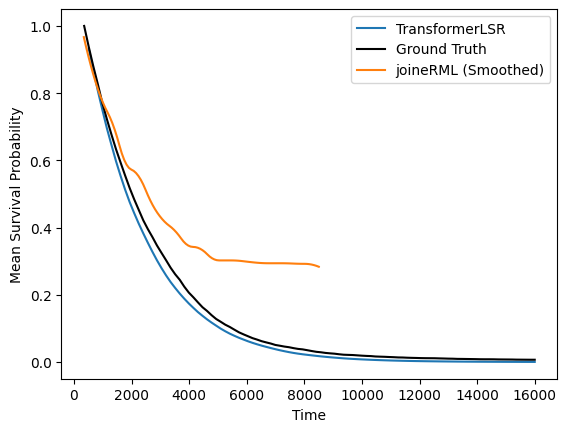

In [6]:
# Plotting Mean survival curve
for i in range(5):

    seed = i + 1

    # LSR
    pred_times = np.array(df_mean_surv.loc[i,"pred_times_plot"])
    mean_surv = np.array(df_mean_surv.loc[i,"mean_surv_plot"])

    valid_idx = pred_times >= df["LT"][i]

    # GT
    with open(f"results/predict_survival_seed_{seed}.pkl", "rb") as f:
        result_surv = pickle.load(f)
    print(f"Seed {seed}:", result_surv.keys())

    # joineRML
    joinerml = pd.read_csv(
        f"{eval_data_path}/mean_surv_smooth_joinerml_seed_{seed}.csv"
    )
    
    plt.figure()
    # LSR
    plt.plot(pred_times[valid_idx], mean_surv[valid_idx], label="TransformerLSR")
    # GT
    plt.plot(result_surv["plot_times"], result_surv["mean_oracle_surv"], color="black", label="Ground Truth")
    # joineRML
    #plt.plot(joinerml.iloc[:, 1], joinerml.iloc[:, 2], label="joineRML")
    plt.plot(joinerml.iloc[:, 1], joinerml.iloc[:, 3], label="joineRML (Smoothed)")
    

    plt.xlabel("Time")
    plt.ylabel("Mean Survival Probability")
    plt.legend()
    plt.show()

Seed 1: dict_keys(['LT', 'plot_times', 'eligible_test_ids', 'test_ids', 'n_paths', 'horizon', 'oracle_surv_by_patient', 'mean_oracle_surv', 'start_rows', 'mc_seed'])


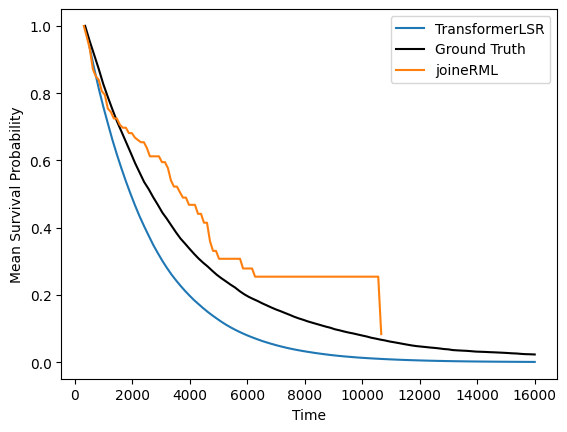

Seed 2: dict_keys(['LT', 'plot_times', 'eligible_test_ids', 'test_ids', 'n_paths', 'horizon', 'oracle_surv_by_patient', 'mean_oracle_surv', 'start_rows', 'mc_seed'])


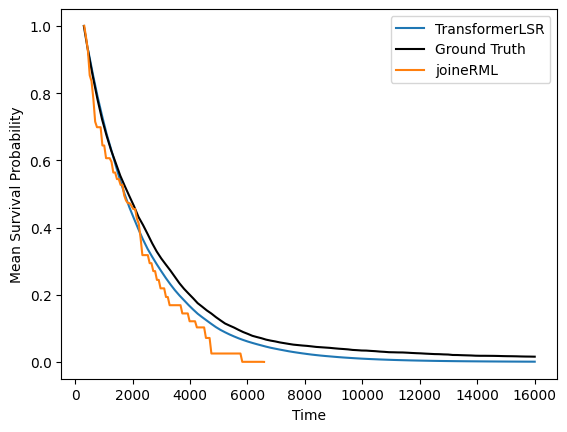

Seed 3: dict_keys(['LT', 'plot_times', 'eligible_test_ids', 'test_ids', 'n_paths', 'horizon', 'oracle_surv_by_patient', 'mean_oracle_surv', 'start_rows', 'mc_seed'])


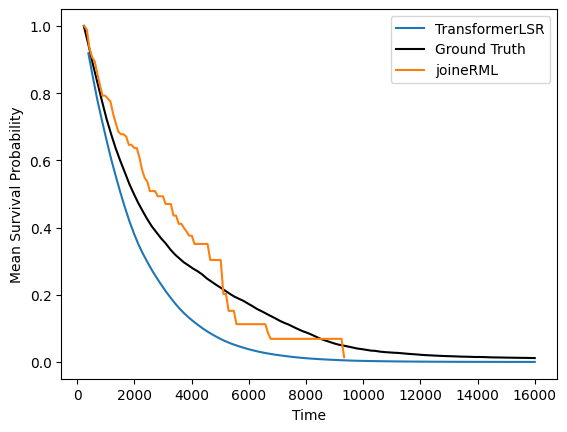

Seed 4: dict_keys(['LT', 'plot_times', 'eligible_test_ids', 'test_ids', 'n_paths', 'horizon', 'oracle_surv_by_patient', 'mean_oracle_surv', 'start_rows', 'mc_seed'])


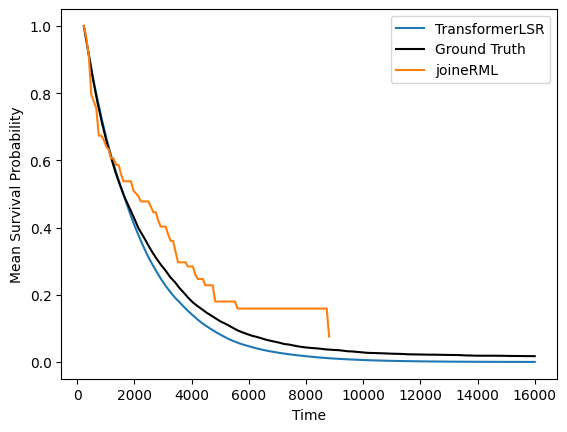

Seed 5: dict_keys(['LT', 'plot_times', 'eligible_test_ids', 'test_ids', 'n_paths', 'horizon', 'oracle_surv_by_patient', 'mean_oracle_surv', 'start_rows', 'mc_seed'])


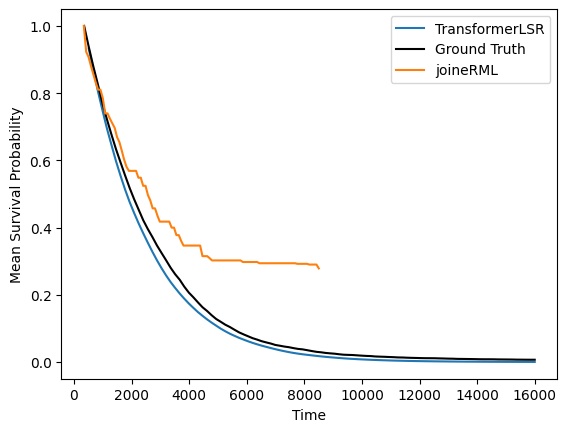

In [8]:
# Plotting Mean survival curve
for i in range(5):

    seed = i + 1

    # LSR
    pred_times = np.array(df_mean_surv.loc[i,"pred_times_plot"])
    mean_surv = np.array(df_mean_surv.loc[i,"mean_surv_plot"])

    valid_idx = pred_times >= df["LT"][i]

    # GT
    with open(f"results/predict_survival_seed_{seed}.pkl", "rb") as f:
        result_surv = pickle.load(f)
    print(f"Seed {seed}:", result_surv.keys())

    # joineRML
    joinerml = pd.read_csv(
        f"{eval_data_path}/mean_surv_smooth_joinerml_seed_{seed}.csv"
    )
    
    plt.figure()
    # LSR
    plt.plot(pred_times[valid_idx], mean_surv[valid_idx], label="TransformerLSR")
    # GT
    plt.plot(result_surv["plot_times"], result_surv["mean_oracle_surv"], color="black", label="Ground Truth")
    # joineRML
    plt.plot(joinerml.iloc[:, 1], joinerml.iloc[:, 2], label="joineRML")
    #plt.plot(joinerml.iloc[:, 1], joinerml.iloc[:, 3], label="joineRML (Smoothed)")
    

    plt.xlabel("Time")
    plt.ylabel("Mean Survival Probability")
    plt.legend()
    plt.show()